# 02 · Base table and data quality

Joins the Overture tract aggregates, the strata and ACS housing units into one row per scored tract, adds size-free features, checks that the numbers are internally consistent, and maps what is missing. Saves `eda_outputs/base_table.parquet`, which every later notebook reads.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))

## 1. Join the primary sources on GEOID
The strata table also carries building, housing-unit and population counts from USFS and CarbonPlan layers (`usfs_BuildingCount_sum`, `usfs_HUCount_sum`, `usfs_PopCount_sum`, `carbonplan_buildings`). They are independent building-count references, which the challenge forbids using to approximate the hidden target, so they are **left out of the base table**. ACS housing units, which the organisers name as a permitted sanity check, are kept.

In [2]:
agg = pd.read_parquet(ANALYSIS / "tract_overture_aggregates.parquet"); stp = pd.read_parquet(ANALYSIS / "scored_tracts_strata.parquet")
acs = pd.concat([pd.read_csv(DATA / "reference" / r / f"{r}-census-acs-housing.csv", dtype={"GEOID": str}) for r in REG])[["GEOID", "housing_units"]]
keep = ["GEOID", "state_usps", "ALAND", "AWATER", "INTPTLAT", "INTPTLON", "pop_total", "pop_urban", "pop_rural", "pct_urban", "ur_class",
        "svi_overall", "svi_socioeconomic", "svi_household", "svi_minority", "svi_housing_transport", "cvi_overall", "cvi_baseline", "cvi_climate",
        "ruca_primary", "ruca_primary_desc", "rucc_2023", "rucc_metro", "tribal_any", "tribal_pct", "tribal_legal", "tribal_statistical", "aiannh_name",
        "usdm_summer_dsci", "usdm_winter_dsci", "pmdi_mean", "spi12_mean", "usfs_WHP_mean",
        "epht_heat_days_summer", "gehe_wbgt28_days_mean", "hwd_maxtemp_mean", "mtbs_wildfire_ever", "mtbs_wildfire_burned_pct_land", "fod_fires"]
df = agg.merge(stp[keep], on="GEOID", how="left", validate="1:1").merge(acs, on="GEOID", how="left", validate="1:1")
for c in ["INTPTLAT", "INTPTLON"]: df[c] = df[c].astype(float)
print("rows:", len(df), "| columns:", df.shape[1], "| tracts with no ACS housing value:", int(df.housing_units.isna().sum()), "| no strata row:", int(df.ALAND.isna().sum()))
print("region sizes:", df.region.value_counts().reindex(REG).to_dict())

rows: 9794 | columns: 82 | tracts with no ACS housing value: 0 | no strata row: 0
region sizes: {'maricopa-az': 1593, 'northern-ca': 591, 'eastern-ok': 1192, 'south-central-tx': 6003, 'eastern-wa': 415}


**Takeaway:** the join is clean: 9,794 rows, one per scored tract, with ACS housing units and a strata row for every tract (the merge enforces one-to-one). The table has 82 columns at this point.

## 2. Structural missing values: a missing count means none
The Overture aggregates leave a count empty when the tract has no feature of that kind (no motorway, no rail, no transit stop). Those are zeros, not unknowns, so they are filled with 0. Two all-water tracts have no features of any kind.

all-water tracts with no features at all: ['48039990000', '48057990000'] | land km2: [0.0, 0.0]


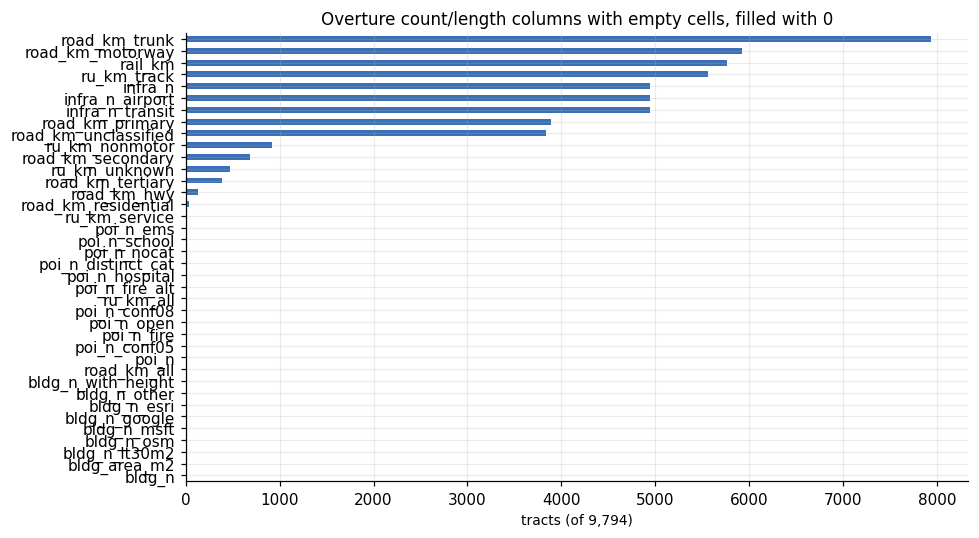

road_km_trunk           7932
road_km_motorway        5921
rail_km                 5763
ru_km_track             5564
infra_n_transit         4939
infra_n_airport         4939
infra_n                 4939
road_km_primary         3894
road_km_unclassified    3835
ru_km_nonmotor           924
road_km_secondary        687
ru_km_unknown            468
road_km_tertiary         386
road_km_hwy              136
road_km_residential       40
ru_km_service              7
bldg_n_google              2
bldg_n_msft                2
bldg_area_m2               2
bldg_n                     2
bldg_n_osm                 2
bldg_n_lt30m2              2
ru_km_all                  2
bldg_n_with_height         2
bldg_n_other               2
bldg_n_esri                2
road_km_all                2
poi_n                      2
poi_n_conf05               2
poi_n_conf08               2
poi_n_open                 2
poi_n_fire                 2
poi_n_ems                  2
poi_n_school               2
poi_n_hospital

In [3]:
cnt = [c for c in df.columns if c.startswith(("bldg_n", "road_km", "ru_km", "rail_km", "infra_n", "poi_n")) or c == "bldg_area_m2"]
before = df[cnt].isna().sum(); water = df[df.bldg_n.isna()]
print("all-water tracts with no features at all:", water.GEOID.tolist(), "| land km2:", water.land_km2.tolist() if "land_km2" in water else (water.ALAND / 1e6).tolist())
df[cnt] = df[cnt].fillna(0)
fig, ax = plt.subplots(figsize=(9, 5)); before[before > 0].sort_values().plot.barh(ax=ax, color="#3b6fb6"); ax.set_title("Overture count/length columns with empty cells, filled with 0"); ax.set_xlabel("tracts (of 9,794)")
plt.tight_layout(); plt.show(); print(before[before > 0].sort_values(ascending=False).astype(int).to_string())

**Takeaway:** an empty count means the feature is absent. Trunk roads are empty in 7,932 tracts (81%), motorways in 5,921 (60%), rail in 5,763 (59%) and transit stops in 4,939 (50%), so these columns are mostly zeros and need to be read as 'none here'. Highway length is empty in 136 tracts. Two all-water Texas tracts (land area 0) have no buildings, roads or POIs of any kind.

## 3. Derived features
Counts depend on tract size, so every count gets a size-free version: per area, per resident, per building, or a share. Division by zero becomes missing, never infinity.

In [4]:
def div(a, b): return (a / b.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
df["land_km2"] = df.ALAND / 1e6; df["water_share"] = div(df.AWATER, df.ALAND + df.AWATER); df["pop_density"] = div(df.pop_total, df.land_km2)
df["bldg_per_km2"] = div(df.bldg_n, df.land_km2); df["bldg_per_hu"] = div(df.bldg_n, df.housing_units); df["hu_per_km2"] = div(df.housing_units, df.land_km2)
df["road_km_per_km2"] = div(df.road_km_all, df.land_km2); df["hwy_share_of_road_km"] = div(df.road_km_hwy, df.road_km_all)
df["poi_per_1k_pop"] = div(df.poi_n * 1000, df.pop_total); df["poi_per_100_bldg"] = div(df.poi_n * 100, df.bldg_n); df["poi_per_km2"] = div(df.poi_n, df.land_km2)
for k, c in {"osm": "bldg_n_osm", "msft": "bldg_n_msft", "esri": "bldg_n_esri", "google": "bldg_n_google"}.items(): df[f"share_{k}"] = div(df[c], df.bldg_n)
df["tiny_share"] = div(df.bldg_n_lt30m2, df.bldg_n); df["height_share"] = div(df.bldg_n_with_height, df.bldg_n); df["conf05_share"] = div(df.poi_n_conf05, df.poi_n)
df["tribal"] = df.tribal_any.astype(bool); df["rural"] = (df.ur_class == "Rural"); df["no_fire_poi"] = df.poi_n_fire == 0; df["no_ems_poi"] = df.poi_n_ems == 0; df["no_transit"] = df.infra_n_transit == 0
new = [c for c in df.columns if c not in agg.columns and c not in keep and c != "housing_units"]
print(len(new), "derived columns:", new); print("infinite values left:", int(np.isinf(df.select_dtypes("number")).sum().sum()))

23 derived columns: ['land_km2', 'water_share', 'pop_density', 'bldg_per_km2', 'bldg_per_hu', 'hu_per_km2', 'road_km_per_km2', 'hwy_share_of_road_km', 'poi_per_1k_pop', 'poi_per_100_bldg', 'poi_per_km2', 'share_osm', 'share_msft', 'share_esri', 'share_google', 'tiny_share', 'height_share', 'conf05_share', 'tribal', 'rural', 'no_fire_poi', 'no_ems_poi', 'no_transit']
infinite values left: 0


**Takeaway:** 23 size-free columns were added (densities, per-resident and per-building rates, source shares, tribal / rural / no-facility flags). Dividing by zero gives missing, and no infinite values remain.

## 4. Internal consistency: do the numbers add up?

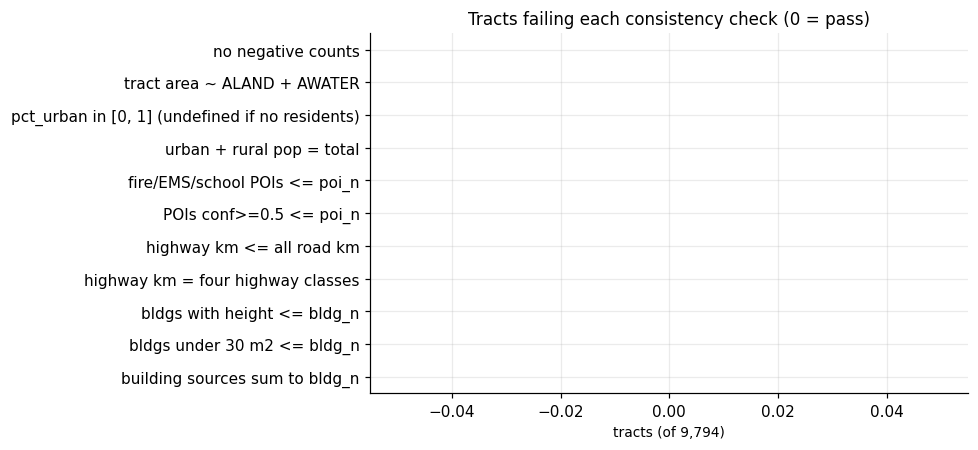

                                                 fail
building sources sum to bldg_n                      0
bldgs under 30 m2 <= bldg_n                         0
bldgs with height <= bldg_n                         0
highway km = four highway classes                   0
highway km <= all road km                           0
POIs conf>=0.5 <= poi_n                             0
fire/EMS/school POIs <= poi_n                       0
urban + rural pop = total                           0
pct_urban in [0, 1] (undefined if no residents)     0
tract area ~ ALAND + AWATER                         0
no negative counts                                  0


In [5]:
chk = {
 "building sources sum to bldg_n": (df[["bldg_n_osm", "bldg_n_msft", "bldg_n_google", "bldg_n_esri", "bldg_n_other"]].sum(axis=1) == df.bldg_n),
 "bldgs under 30 m2 <= bldg_n": df.bldg_n_lt30m2 <= df.bldg_n, "bldgs with height <= bldg_n": df.bldg_n_with_height <= df.bldg_n,
 "highway km = four highway classes": np.isclose(df.road_km_hwy, df[["road_km_motorway", "road_km_trunk", "road_km_primary", "road_km_secondary"]].sum(axis=1), atol=1e-6),
 "highway km <= all road km": df.road_km_hwy <= df.road_km_all + 1e-6,
 "POIs conf>=0.5 <= poi_n": df.poi_n_conf05 <= df.poi_n, "fire/EMS/school POIs <= poi_n": (df.poi_n_fire + df.poi_n_ems + df.poi_n_school) <= df.poi_n,
 "urban + rural pop = total": (df.pop_urban + df.pop_rural - df.pop_total).abs() <= 1, "pct_urban in [0, 1] (undefined if no residents)": df.pct_urban.between(0, 1) | (df.pct_urban.isna() & (df.pop_total == 0)),
 "tract area ~ ALAND + AWATER": np.isclose(df.tract_area_km2, (df.ALAND + df.AWATER) / 1e6, rtol=.02), "no negative counts": (df.select_dtypes("number").filter(regex="_n|_km|pop_|housing").min(axis=1) >= 0)}
R = pd.DataFrame({k: {"fail": int((~pd.Series(np.asarray(v), dtype="boolean").fillna(False).astype(bool)).sum())} for k, v in chk.items()}).T
fig, ax = plt.subplots(figsize=(9, 4.2)); R.fail.sort_values().plot.barh(ax=ax, color=["#6a9e4f" if v == 0 else "#c0504d" for v in R.fail.sort_values()]); ax.set_title("Tracts failing each consistency check (0 = pass)"); ax.set_xlabel("tracts (of 9,794)")
plt.tight_layout(); plt.show(); print(R.to_string())

**Takeaway:** after the zero fill every check passes: building source counts add up to the total, highway km equals its four classes and never exceeds all road km, sub-counts never exceed their totals, urban plus rural population equals total, and tract area matches census land plus water. Before the fill, 136 tracts failed the highway checks only because their highway length was empty.

## 5. Missing values: where and why?

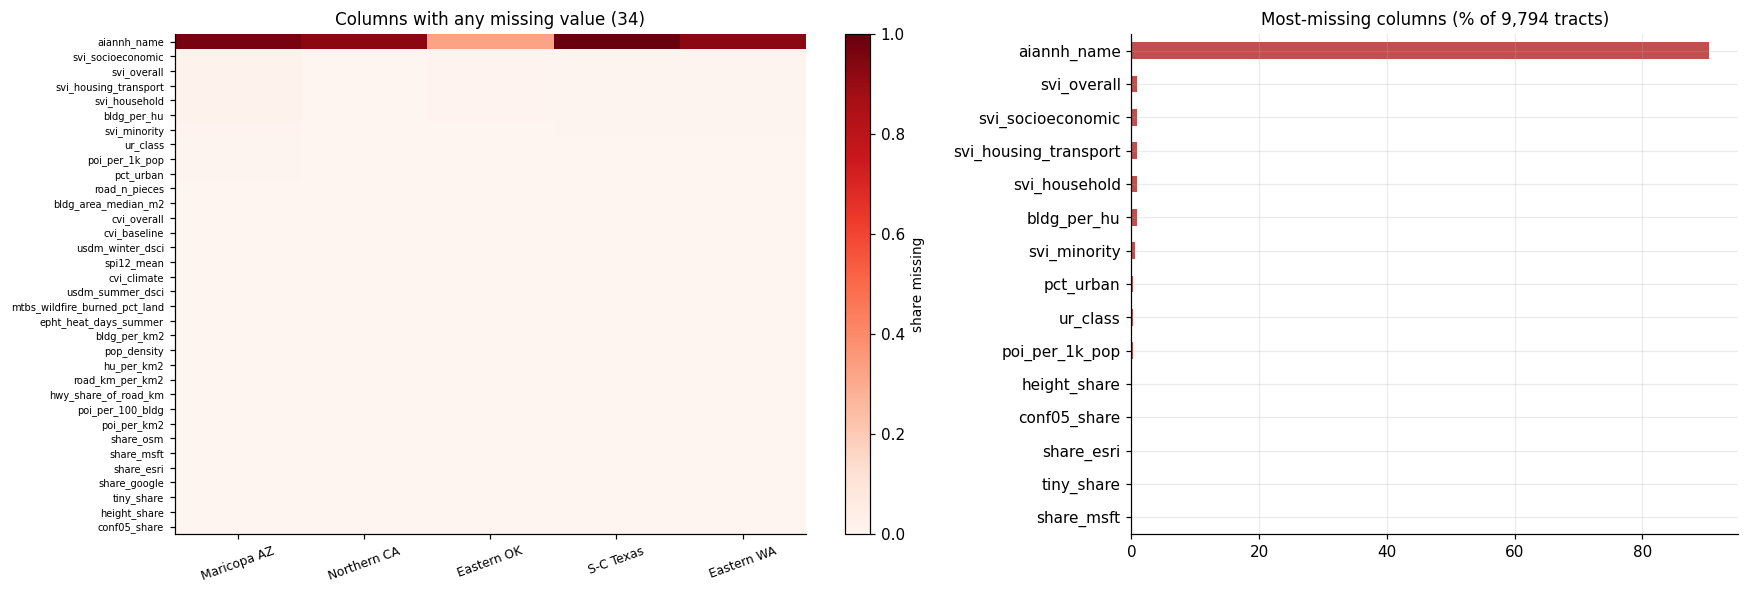

region                 maricopa-az  northern-ca  eastern-ok  south-central-tx  eastern-wa   max
aiannh_name                   0.97         0.92        0.32              1.00        0.93  1.00
svi_socioeconomic             0.02         0.00        0.01              0.01        0.01  0.02
svi_overall                   0.02         0.00        0.01              0.01        0.01  0.02
svi_housing_transport         0.02         0.00        0.01              0.01        0.01  0.02
svi_household                 0.02         0.00        0.01              0.01        0.01  0.02
bldg_per_hu                   0.02         0.00        0.01              0.01        0.00  0.02
svi_minority                  0.01         0.00        0.00              0.00        0.00  0.01
ur_class                      0.01         0.00        0.00              0.00        0.00  0.01
poi_per_1k_pop                0.01         0.00        0.00              0.00        0.00  0.01
pct_urban                     0.01      

In [6]:
miss = df.isna().groupby(df.region).mean().T.reindex(columns=REG); miss = miss[miss.max(axis=1) > 0].sort_values(REG[0], ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
im = ax[0].imshow(miss.values, aspect="auto", cmap="Reds", vmin=0, vmax=1); ax[0].grid(False); ax[0].set_xticks(range(5)); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=8, rotation=20)
ax[0].set_yticks(range(len(miss))); ax[0].set_yticklabels(miss.index, fontsize=6.5); plt.colorbar(im, ax=ax[0], label="share missing"); ax[0].set_title(f"Columns with any missing value ({len(miss)})")
(df.isna().mean()[df.isna().mean() > 0] * 100).sort_values().tail(15).plot.barh(ax=ax[1], color="#c0504d"); ax[1].set_title("Most-missing columns (% of 9,794 tracts)")
plt.tight_layout(); plt.show()
print(miss.assign(max=miss.max(axis=1)).sort_values("max", ascending=False).head(14).round(2).to_string())
print("\nrows with any missing derived ratio:", int(df[["poi_per_100_bldg", "bldg_per_hu", "poi_per_1k_pop", "road_km_per_km2"]].isna().any(axis=1).sum()))

**Takeaway:** the remaining missing values are few and explainable. `aiannh_name` is empty for tracts not on tribal land (all of Texas, 92-97% of Arizona, California and Washington, 32% of Oklahoma). SVI and the ratios built on residents or housing are missing for about 1-2% of tracts, and 82 tracts have at least one missing derived ratio (zero residents or zero housing units).

## 6. Zeros that may be structural

                  no buildings  no roads  no highway road  no POIs  zero population  zero housing units
region                                                                                                 
maricopa-az                  0         0               33        0               11                  27
northern-ca                  0         0                7        0                0                   0
eastern-ok                   0         0               28        0                1                  10
south-central-tx             2         2               64        2               14                  43
eastern-wa                   0         0                5        0                1                   2

total: {'no buildings': 2, 'no roads': 2, 'no highway road': 137, 'no POIs': 2, 'zero population': 27, 'zero housing units': 82}

tracts with zero population or housing: 82 | of those with buildings: 80 | median land km2: 4.9


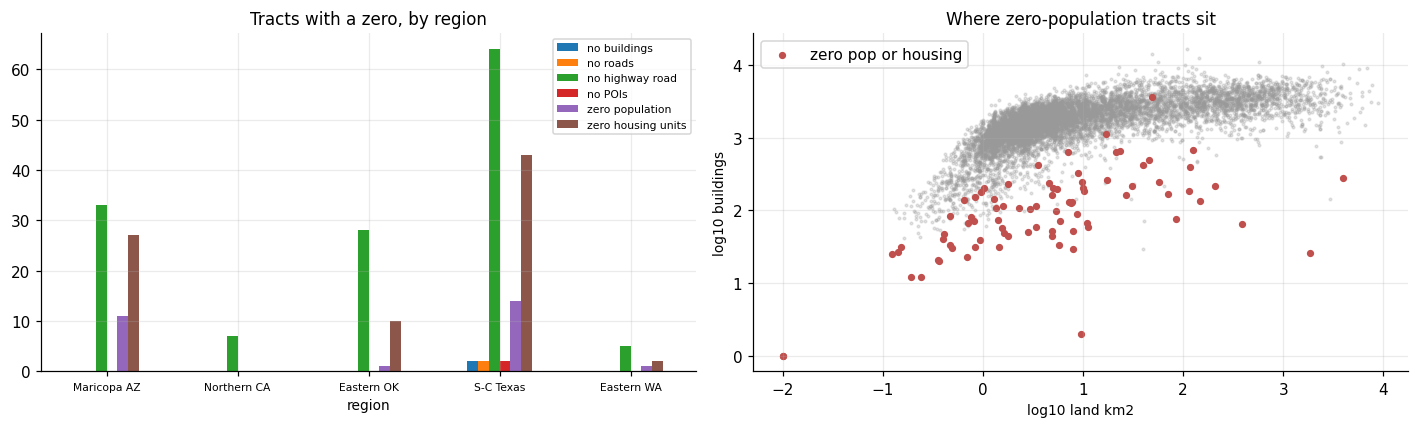

In [7]:
zero = pd.DataFrame({"no buildings": df.bldg_n == 0, "no roads": df.road_km_all == 0, "no highway road": df.road_km_hwy == 0, "no POIs": df.poi_n == 0, "zero population": df.pop_total == 0, "zero housing units": df.housing_units == 0}).groupby(df.region).sum().reindex(REG)
print(zero.to_string()); print("\ntotal:", zero.sum().to_dict())
z = df[(df.pop_total == 0) | (df.housing_units == 0)]; print("\ntracts with zero population or housing:", len(z), "| of those with buildings:", int((z.bldg_n > 0).sum()), "| median land km2:", round(z.land_km2.median(), 1))
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); zero.plot.bar(ax=ax[0], rot=0); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=7); ax[0].legend(fontsize=7); ax[0].set_title("Tracts with a zero, by region")
ax[1].scatter(np.log10(df.land_km2.clip(lower=.01)), np.log10(df.bldg_n.clip(lower=1)), s=3, alpha=.25, color="#999"); ax[1].scatter(np.log10(z.land_km2.clip(lower=.01)), np.log10(z.bldg_n.clip(lower=1)), s=14, color="#c0504d", label="zero pop or housing"); ax[1].legend(); ax[1].set(xlabel="log10 land km2", ylabel="log10 buildings", title="Where zero-population tracts sit")
plt.tight_layout(); plt.show()

**Takeaway:** 137 tracts (1.4%) have no highway-class road (33 Maricopa, 28 Eastern OK, 64 Texas, 7 California, 5 Washington). 82 tracts have zero housing units and 27 zero residents; 80 of those 82 still contain buildings and their median land area is 4.9 km2, so they look like parks, industrial or institutional land. Per-resident rates are undefined for them and need explicit handling. The two all-water Texas tracts are the only ones with no buildings, roads or POIs.

## 7. Save the base table

In [8]:
OUT.mkdir(exist_ok=True); df.to_parquet(OUT / "base_table.parquet", index=False)
chk_ = pd.read_parquet(OUT / "base_table.parquet"); print("saved:", chk_.shape, "| GEOID unique:", chk_.GEOID.is_unique, "| size MB:", round((OUT / "base_table.parquet").stat().st_size / 1e6, 2))

saved: (9794, 105) | GEOID unique: True | size MB: 4.67


**Takeaway:** saved 9,794 rows by 105 columns with a unique GEOID. Later notebooks start from this file.